# Uniaxial compression

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xara
from xara.units import create_units

if "thesis" in plt.style.available:
    plt.style.use("thesis")

units = create_units(length="inch", force="kip")

## Common parameters

Use the same concrete properties and fracture energies as the study. The strain history follows its compression envelope. Stress and strain are negative in compression.

In [2]:
fc = -8.5 * units.ksi
Ec = 57 * units.ksi * np.sqrt(abs(fc) / units.psi)
nu = 0.2
ec0 = -0.003
ft = abs(0.14 * fc)

alpha = 0.1

aC = 4.0
Fco = abs(fc) * 4*aC / (1 + aC)**2

Gt = 0.073 * (abs(fc) / units.MPa)**0.18 * units.kN / units.m
Gc = 2.0 * (abs(fc) / ft)**2 * Gt

Lc = 1 * units.inch
Ap = 1/((Gt*Ec)/(Lc*ft**2) - 0.5)

strain_history = np.linspace(0.0, 5 * ec0, 200)
print(f"{Ap = }")

Xo = 0.6*abs(fc)*units.ksi #abs(fc)*2

Ap = np.float64(0.3678139527218994)


## Loading test

`UniaxialTest` builds a unit cube with one `SSPbrick`. 
The bottom and two side coordinate planes prevent rigid motion; the other side faces are free. 
The top face moves uniformly in the axial direction. Displacement control follows the prescribed strain history, including post-peak softening. An optional `configure(model, material_tag, element_tag)` callback can set material stages before analysis.

In [3]:
from xara.examples.material import UniaxialTest

In [4]:
uniaxial_test = UniaxialTest(strain_history)

## Compression envelope

Faria is the multiaxial material active in the study. Lee–Fenves uses the configuration commented out there, with `alpha=0.1` added for this illustration; its parameters have not been fitted to the Faria curve.

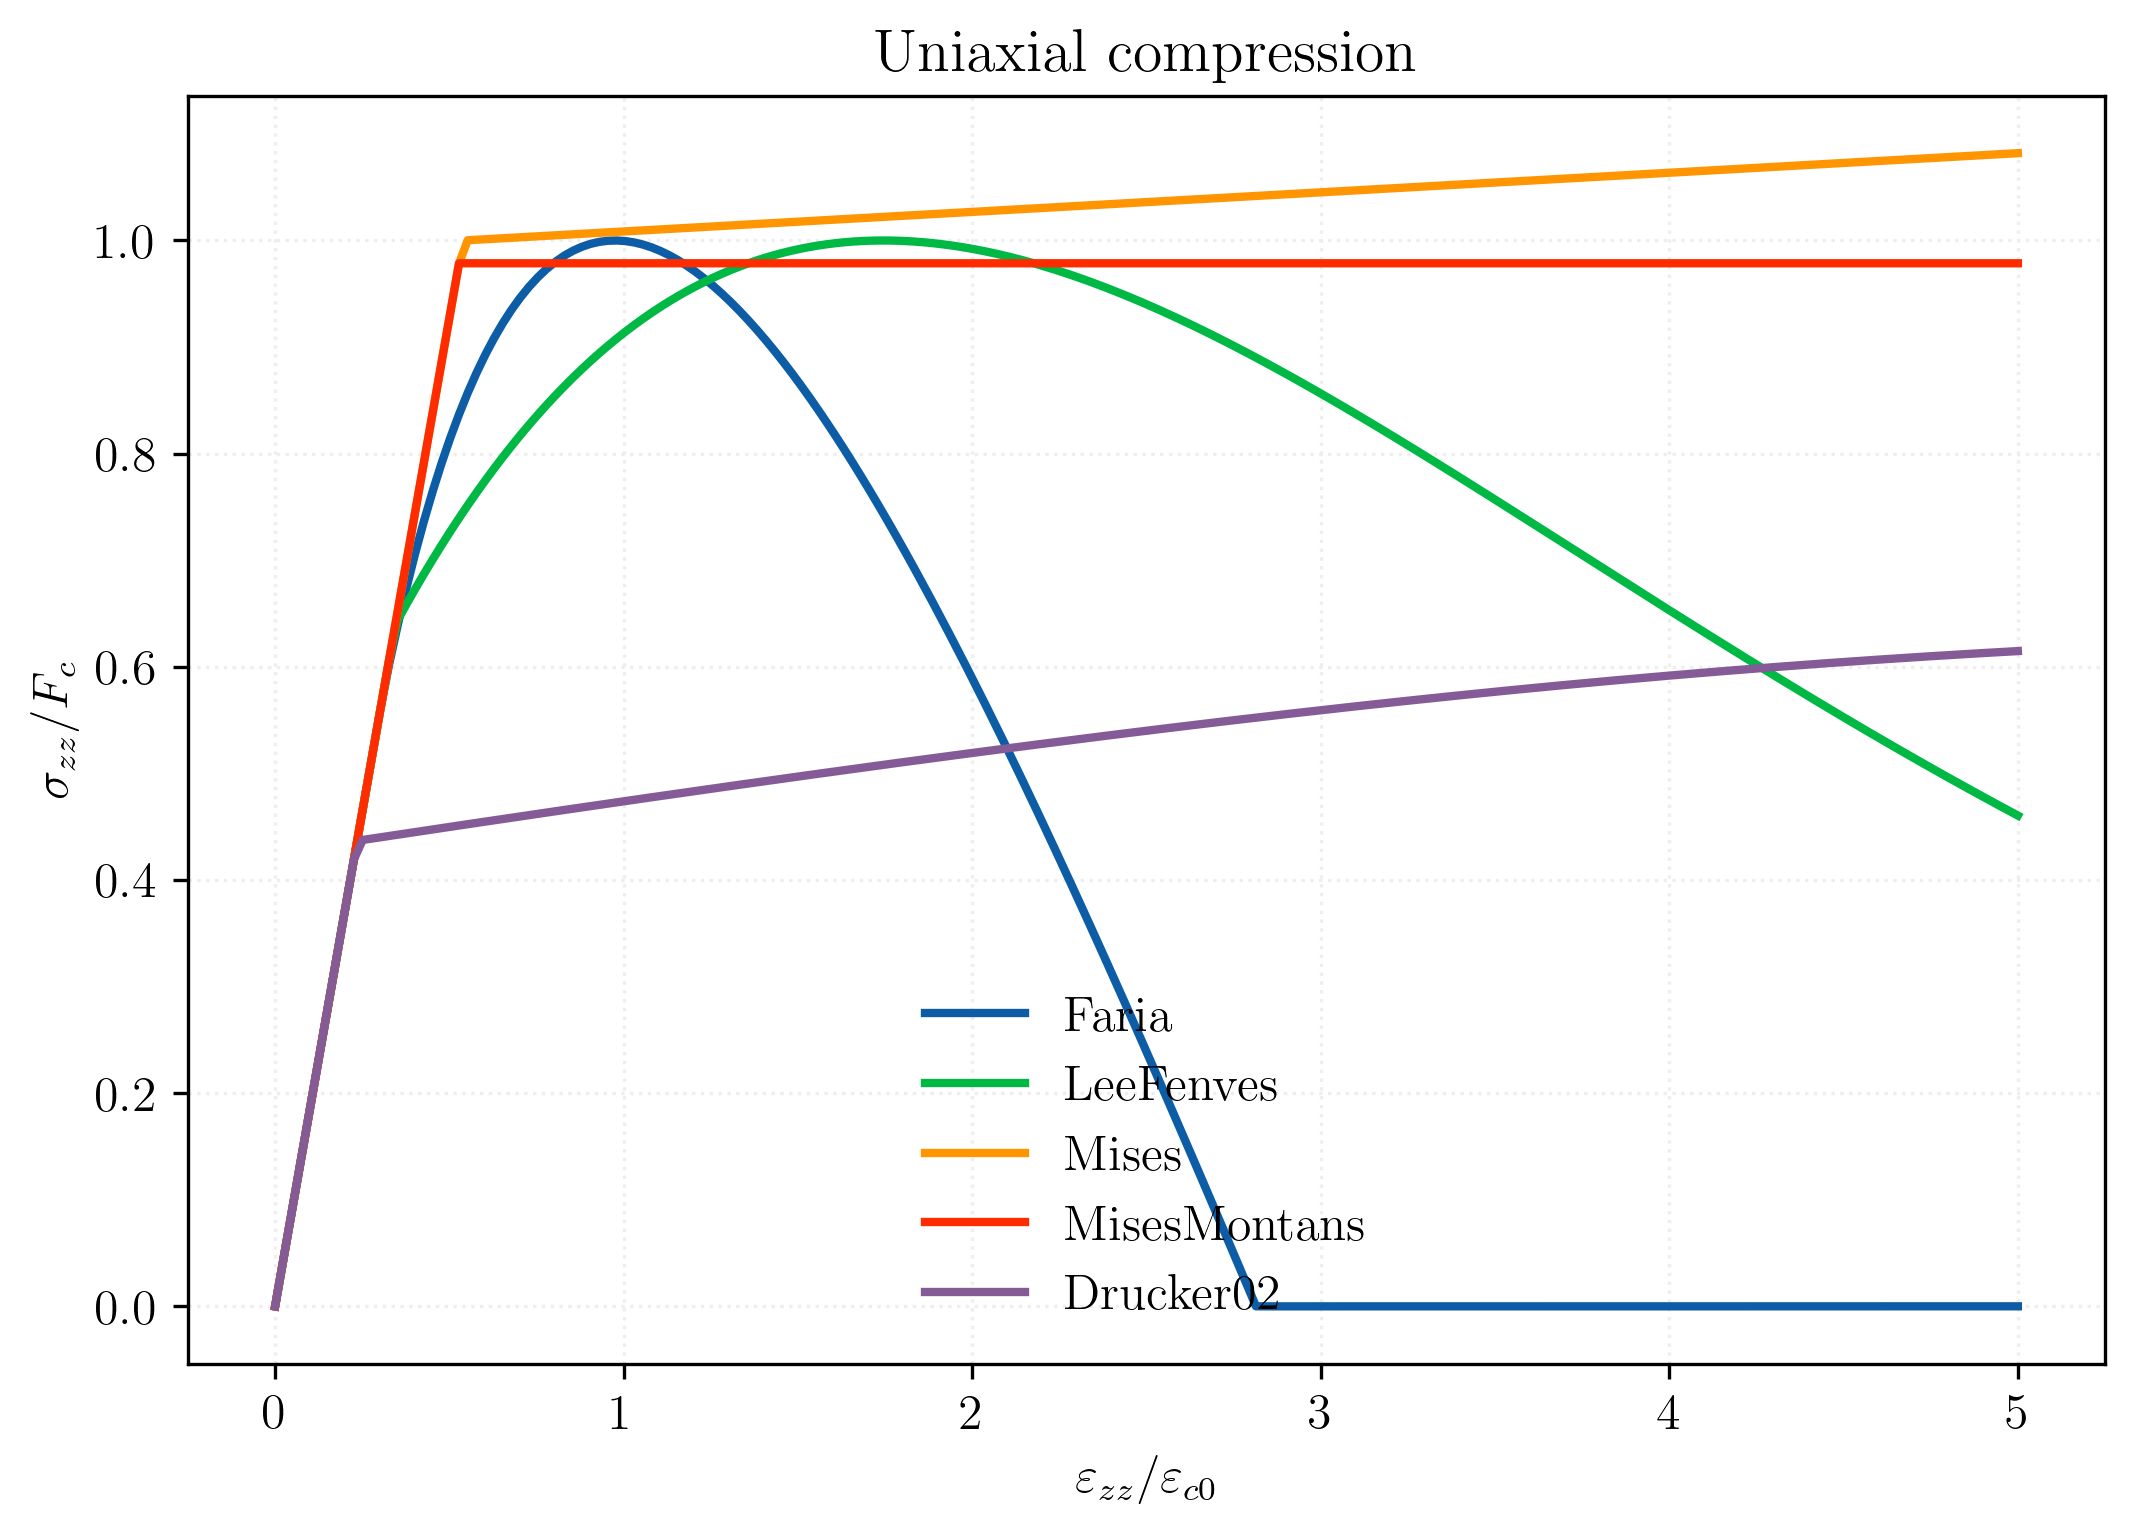

In [5]:
material_models = {
    "Faria": xara.MultiaxialMaterial(
        "FariaPlasticDamage",
        E=Ec, nu=nu, Fc=fc, 
        scale_peak=True,
        Ft=ft, beta=0.0, 
        Ap=Ap, #2.5, 
        An=3, 
        Bn=0.75,
    ),
    "LeeFenves": xara.MultiaxialMaterial(
        "LeeFenves", E=Ec, nu=nu, 
        Fc=Fco, #/(1.0-alpha), 
        Ft=ft, 
        Gc=Gc, 
        Gt=Gt,
        Lc=Lc, 
        Lt=Lc,
        aC=aC,
        Dc=0.4,
        alphap=0.2, 
        alpha=alpha,
    ),
    "Mises": xara.MultiaxialMaterial(
        "PlasticJ2", E=Ec, nu=nu, Fy=abs(fc),
        Hiso=0.01*Ec,
        Hkin=0.0,
    ),
    "MisesMontans": xara.MultiaxialMaterial(
        "MisesBoundingSurface", E=Ec, nu=nu, 
        Fy=abs(fc),
        Fs=1.0*abs(fc),
        Hy=0, #0.1*Ec,
        m=1,
        h=0.9*Ec,
        H0=0
    ),
    "Drucker02": xara.MultiaxialMaterial(
        "DruckerPlasticity02", E=Ec, nu=nu,
        alpha=abs(Fco)*(np.sqrt(2/3) - alpha),
        gamma=0,
        beta=0.0,
        theta=alpha,
        Xo=Xo,
        D=1/Xo,
        T=ft,
        W=0.08,
        R=1,
    ),
}

results = {
    label: uniaxial_test.run(material, label)
    for label, material in material_models.items()
}

fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
for label, result in results.items():
    ax.plot(result.axial_strain/ec0,  result.axial_stress / fc,
            lw=2, label=label)

ax.set_xlabel(r"$\varepsilon_{zz}/\varepsilon_{c0}$")
ax.set_ylabel(r"$\sigma_{zz}/F_c$")
ax.set_title("Uniaxial compression")
ax.legend();

## Numerical checks

Verify the prescribed axial strain and that the lateral stresses remain zero.

In [6]:
for label, result in results.items():
    np.testing.assert_allclose(result.axial_strain, strain_history, atol=1e-10)
    np.testing.assert_allclose(result.stress[:, [0, 1, 3, 4, 5]], 0.0,
                               atol=1e-6 * abs(fc))
    assert np.isfinite(result.strain).all() and np.isfinite(result.stress).all()
    print(f"{label}: peak compression = {-result.axial_stress.min()/units.ksi:.3f} ksi")
print("Checks passed.")

Faria: peak compression = 8.500 ksi
LeeFenves: peak compression = 8.500 ksi
Mises: peak compression = 9.196 ksi
MisesMontans: peak compression = 8.318 ksi
Drucker02: peak compression = 5.226 ksi
Checks passed.
